In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.covariance import LedoitWolf

from MirrorFeatureExtractor.baseline import (
    extract_photometric,
    new_extract_edge_features,
    proces_one_img,
    robust_z
)
from MirrorExtractor.simple_mirror_extractor import SimpleMirrorExtractor

from DetectionMetrics.detection_metrics import DetectionMetrics, compute_metrics

from tools import show_img, mark_mirrors_on_img

In [2]:
# test_img_json_path =  "/media/pgliwny/ADATA HD3304/Computer_vision_for_MAGIC/data/img_with_annomarly.json"
test_img_json_path = "/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/annotations/img_annomarly_05.json"
with open(test_img_json_path) as f:
    json_metadata_list = json.load(f)

print(json_metadata_list[0])
print(len(json_metadata_list))

{'file': '20240505_1800_la.jpg', 'marked_mirrors': [152, 190]}
17


In [3]:
BASELINE_OUT_FILE = "/home/pgliwny/Praca/Computer_vision_for_MAGIC/scripts/scripts_for_baseline/output/out_baseline_webcam.npz"
CALIB_FILE = "/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/calibration/points_WebCam.json"
IMG_DIR_PATH = Path("/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good")
mirror_extractor = SimpleMirrorExtractor(CALIB_FILE)

# Load baseline model
b = np.load(BASELINE_OUT_FILE, allow_pickle=False)
lw = LedoitWolf()
lw.covariance_ = b["covariance"]
lw.location_ = b["location"]
lw.precision_ = np.linalg.pinv(b["covariance"])
print(b["threshold"])

[5.99232958 6.54647574 5.03801032 4.79550282 4.35190783 6.72090424
 4.46388103 7.64577313 5.1822998  5.03354076 5.71739727 5.24427811
 5.39692424 5.76090534 6.86731032 4.33419792 6.00450056 5.66433158
 8.46263849 5.95874706 5.51426234 5.20628462 6.1168803  5.48605715
 6.32699402 6.11771318 6.3605189  7.1150816  5.19715772 5.4967971
 5.8176932  6.72351214 3.54797979 4.68410916 5.78674047 4.01721576
 6.53870845 7.77646176 5.64676749 7.18335019 8.04388908 4.00808567
 4.13643803 4.72773128 5.16596218 4.94807177 5.44995923 6.74077765
 5.48931894 7.41017315 6.83621374 6.97551667 6.81359402 8.60811658
 7.68661212 4.21223861 3.19501971 4.28485871 4.64391386 5.45003322
 6.2624804  4.77241336 4.75208358 7.21486401 5.71504946 6.87163388
 6.30028188 6.38050761 6.80903824 6.95081988 5.33500954 5.80595627
 2.73961197 4.5087735  3.73947841 6.08487264 3.15492416 3.97500411
 5.26812177 5.13202205 7.23337431 5.01874316 4.99019991 6.62472895
 4.92846763 4.38689002 7.21797488 7.0477043  6.09343233 5.58897

In [4]:
def calc_metrics(obj_list, lw, baseline, threshold):
    tp_sum = 0
    fp_sum = 0
    fn_sum = 0
    for i, obj in enumerate(obj_list):
        file_name = obj['file']
        img_path = IMG_DIR_PATH / file_name
        X_new = proces_one_img(img_path, mirror_extractor)
        R_new = robust_z(X_new[None, ...], axis=1)[0]
        Z_new = R_new - baseline["mu"]
        d2 = lw.mahalanobis(Z_new)
        score = d2 / baseline["d2_med"]
        outliers_mirrors = np.where(score > threshold)[0]

        ground_truth = obj["marked_mirrors"]
        metrics = compute_metrics(outliers_mirrors, ground_truth)

        tp_sum += metrics.tp
        fp_sum += metrics.fp
        fn_sum += metrics.fn

    precision = tp_sum / (tp_sum + fp_sum)
    recall = tp_sum / (tp_sum + fn_sum)
    print(f"True positive: %d: {tp_sum}")
    print(f"False positive: %d: {fp_sum}")
    print(f"False negative: %d: {fn_sum}")
    print("Summary precision: %.3f", precision)
    print("Summary recall: %.3f", recall)
    return precision, recall


In [7]:
precision_list, recall_list = [], []
threshold_list = [ 1, 2, 3, 4, 5, 8, 11, 14, 17]
for thr in threshold_list:
    print(thr)
    precision, recall = calc_metrics(json_metadata_list, lw, b, thr)
    precision_list.append(precision)
    recall_list.append(recall)

1
True positive: %d: 141
False positive: %d: 2636
False negative: %d: 0
Summary precision: %.3f 0.05077421678069859
Summary recall: %.3f 1.0
2
True positive: %d: 139
False positive: %d: 1435
False negative: %d: 2
Summary precision: %.3f 0.08831003811944091
Summary recall: %.3f 0.9858156028368794
3
True positive: %d: 132
False positive: %d: 885
False negative: %d: 9
Summary precision: %.3f 0.12979351032448377
Summary recall: %.3f 0.9361702127659575
4
True positive: %d: 125
False positive: %d: 636
False negative: %d: 16
Summary precision: %.3f 0.164257555847569
Summary recall: %.3f 0.8865248226950354
5
True positive: %d: 112
False positive: %d: 502
False negative: %d: 29
Summary precision: %.3f 0.18241042345276873
Summary recall: %.3f 0.7943262411347518
8
True positive: %d: 89
False positive: %d: 290
False negative: %d: 52
Summary precision: %.3f 0.23482849604221637
Summary recall: %.3f 0.6312056737588653
11
True positive: %d: 75
False positive: %d: 202
False negative: %d: 66
Summary pre

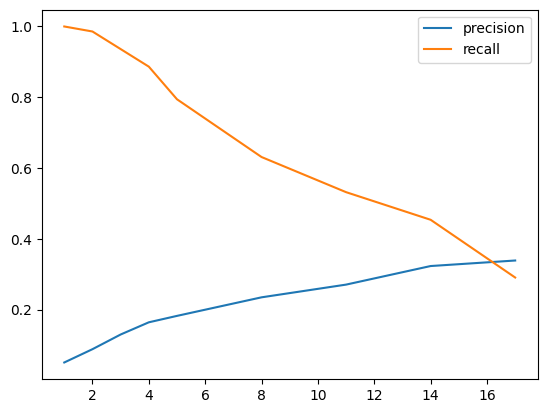

In [9]:
plt.plot(threshold_list, precision_list, label="precision")
plt.plot(threshold_list, recall_list, label="recall")
plt.legend()
plt.show()

[142 231 241]
[152, 190]
Result:        P=0.000 R=0.000 F1=0.000 IoU=0.000 (TP=0, FP=3, FN=2)


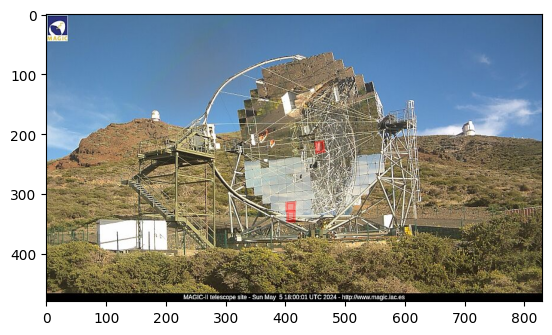

[ 33  76  85 101 102 103 119 120 121 125 138 142 150 151 152 154 168 169
 170 171 172 173 184 189 190 193 204 209]
[150, 151, 152, 153, 154, 168, 169, 170, 171, 172, 189, 190, 191, 204, 206, 207, 221, 222, 235, 236, 246]
Result:        P=0.429 R=0.571 F1=0.490 IoU=0.324 (TP=12, FP=16, FN=9)


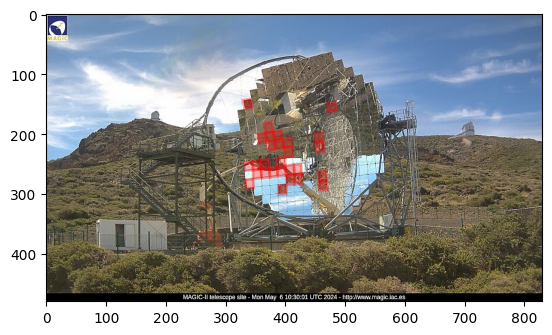

[101 102 119 121 135 142 173 189 190 209]
[152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.300 R=0.333 F1=0.316 IoU=0.188 (TP=3, FP=7, FN=6)


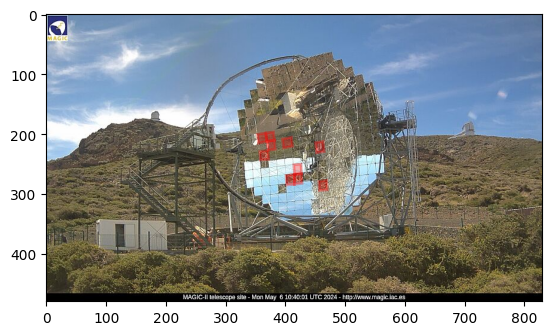

[101 102 119 120 121 135 142 150 151 154 155 156 167 168 169 170 172 173
 184 188 189 190 204 209]
[152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.167 R=0.444 F1=0.242 IoU=0.138 (TP=4, FP=20, FN=5)


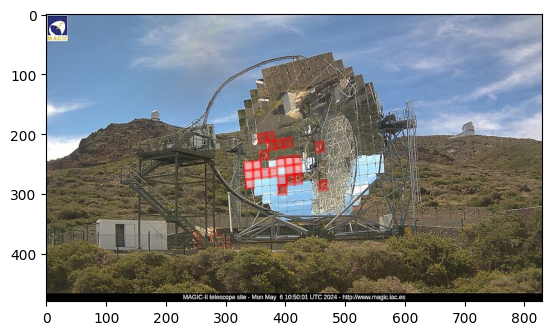

[101 121 135 189 190 193 204 209]
[119, 121, 135, 152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.875 R=0.583 F1=0.700 IoU=0.538 (TP=7, FP=1, FN=5)


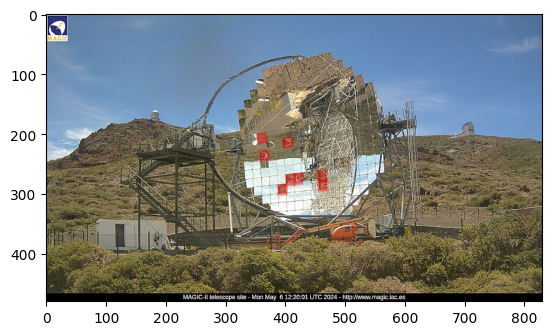

[101 119 121 135 172 173 184 188 189 190 204 209 217 218 219 220 229 230
 231 232 233 243]
[119, 121, 135, 152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.318 R=0.583 F1=0.412 IoU=0.259 (TP=7, FP=15, FN=5)


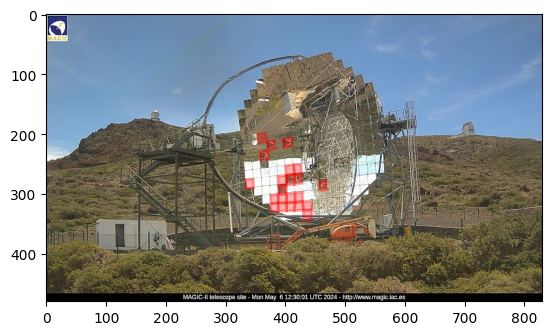

[101 119 121 130 135 189 190 193 204 209]
[119, 121, 135, 152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.800 R=0.667 F1=0.727 IoU=0.571 (TP=8, FP=2, FN=4)


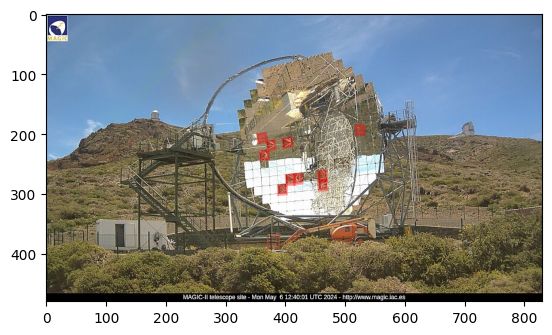

[101 119 135 142 176 179 190 193 209]
[119, 152, 176, 179, 190, 193, 209]
Result:        P=0.667 R=0.857 F1=0.750 IoU=0.600 (TP=6, FP=3, FN=1)


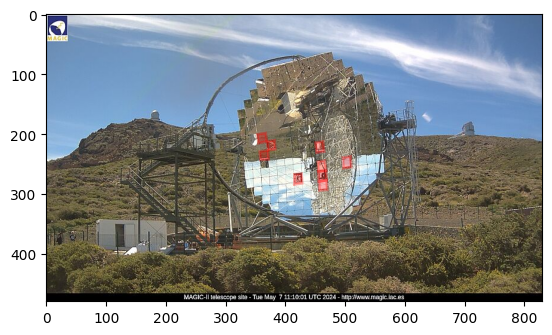

[101 130 135 142 176 179 190 193]
[152, 176, 179, 190, 209]
Result:        P=0.375 R=0.600 F1=0.462 IoU=0.300 (TP=3, FP=5, FN=2)


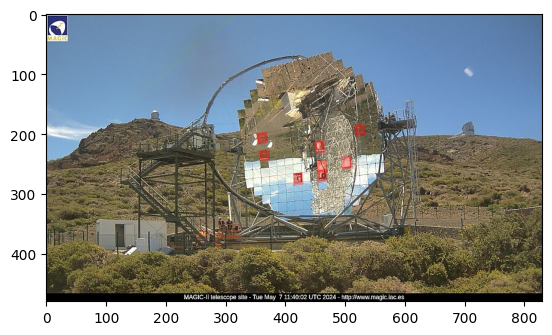

[101 120 135 179 190 193]
[152, 176, 179, 190, 209, 216]
Result:        P=0.333 R=0.333 F1=0.333 IoU=0.200 (TP=2, FP=4, FN=4)


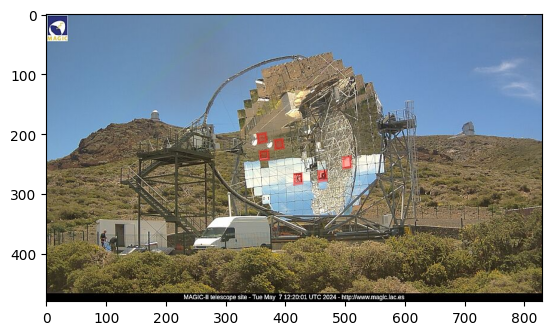

True positive: %d: 52
False positive: %d: 76
False negative: %d: 43
Summary precision: %.3f 0.40625
Summary recall: %.3f 0.5473684210526316


In [5]:
tp_sum = 0
fp_sum = 0
fn_sum = 0

for i, obj in enumerate(json_metadata_list[:10]):
    file_name = obj['file']
    img_path = IMG_DIR_PATH / file_name
    X_new = proces_one_img(img_path, mirror_extractor)
    R_new = robust_z(X_new[None, ...], axis=1)[0]
    Z_new = R_new - b["mu"]
    d2 = lw.mahalanobis(Z_new)
    d2 = lw.mahalanobis(Z_new)
    score = d2 / b["d2_med"]
    outliers_mirrors = np.where(score > 2*b["threshold"])[0]

    ground_truth = obj["marked_mirrors"]
    print(outliers_mirrors)
    print(ground_truth)
    metrics = compute_metrics(outliers_mirrors, ground_truth)
    print(f"Result:        {metrics.summary}")

    points = [mirror_extractor.get_point_coords(m_id) for m_id in outliers_mirrors]
    fig, ax = plt.subplots()
    mark_mirrors_on_img(img_path, points, "red", ax)
    plt.show()

    tp_sum += metrics.tp
    fp_sum += metrics.fp
    fn_sum += metrics.fn

precision = tp_sum / (tp_sum + fp_sum)
recall = tp_sum / (tp_sum + fn_sum)
print(f"True positive: %d: {tp_sum}")
print(f"False positive: %d: {fp_sum}")
print(f"False negative: %d: {fn_sum}")
print("Summary precision: %.3f", precision)
print("Summary recall: %.3f", recall)


In [8]:
score.shape

(249,)

In [ ]:
metrics.tn

In [7]:
obj["marked_mirrors"]

[152, 190]